# Part D: Build the e-commerce review figure (25 marks)

Plan: (1) look before cleaning, (2) fix every fault with a stated rule and count, (3) clean the catalogue, (4) build the 2x2 figure.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from vizlib import PALETTE, style_defaults, save_fig   # Week 3 toolkit
import tslib                                           # Week 4 toolkit

%matplotlib inline
style_defaults()

DATA = Path("data")
FIG = Path("figures"); FIG.mkdir(exist_ok=True)

def save(fig, name, note=None):
    """fig.savefig first (300 dpi, tight), THEN the figure is shown."""
    save_fig(fig, FIG / name, note)

def check(label, ok, detail=""):
    print(f"[{'PASS' if ok else 'FAIL'}] {label} {detail}")

## 1. Look first (the four calls, in this order)

In [2]:
df = pd.read_csv(DATA / "sessions_hourly.csv")
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12670 entries, 0 to 12669
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   ts           12670 non-null  object
 1   sessions     12670 non-null  int64 
 2   orders       12670 non-null  int64 
 3   revenue_pkr  12670 non-null  int64 
 4   device       12670 non-null  object
dtypes: int64(3), object(2)
memory usage: 495.1+ KB


In [3]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
sessions,12670.0,947.951381,646.882994,-1.0,435.0,756.0,1368.00,9811.0
orders,12670.0,30.016732,20.089492,4.0,14.0,24.0,42.00,304.0
revenue_pkr,12670.0,132564.968824,100150.706234,10350.0,58036.5,102359.0,182232.25,1652881.0


In [4]:
df.device.value_counts()

device
Mobile     6994
Desktop    3452
mobile      883
Tablet      777
desktop     318
MOBILE      246
Name: count, dtype: int64

In [5]:
df.ts.head(10).tolist()

['2024-04-29 11:00:00',
 '2024-10-26 05:00:00',
 '2025-08-04 20:00:00',
 '2024-10-05 19:00:00',
 '2025-01-22 20:00:00',
 '05/10/2024 09:00',
 '2024-08-11 15:00:00',
 '12/04/2025 10:00',
 '2024-07-24 02:00:00',
 '2025-03-27 11:00:00']

**What I notice (in my own words):**
- `ts` is plain text (`info()` shows `str`, not datetime) in **two formats** (19 and 16 characters): ISO `yyyy-mm-dd hh:mm:ss` (9,019 rows) and `dd/mm/yyyy hh:mm` (3,651 rows). A default parse turns the 3,651 slash rows into NaT; `format="mixed"` parses them month-first and drags the series out to 2024-01-04 .. 2025-12-08, which is wrong (the real span is 2024-04-01 to 2025-09-11).
- `device` has 6 spellings for 3 devices (`Mobile`, `mobile`, `MOBILE ` with a **trailing space**, `Desktop`, `desktop`, `Tablet`). Title-casing alone leaves 4 labels, so the rule needs `.str.strip()` as well.
- `sessions` has a minimum of -1: a sentinel for "not measured", not a count (287 rows).
- Those are three from the four calls. The fourth thing they only hint at is the day/month order of the slash rows, which only the `min()`/`max()` check settles.
- Three more appear only once the index is a real DatetimeIndex: **286 exact duplicate rows**; **312 hours never recorded**, which are 13 whole days in separate blocks (so `resample("D")` would invent 13 rows); and a **partial final month** (the data stops on 11 Sep 2025, 11 of 30 days).

## 2. The parsing trap
`pd.to_datetime` can succeed on every row and still be wrong. Compare `.min()` and `.max()`, not just the row count.

In [6]:
for name, kw in [("default", {}), ("format='mixed'", {"format": "mixed"}),
                 ("mixed, dayfirst=True", {"format": "mixed", "dayfirst": True})]:
    t = pd.to_datetime(df.ts, errors="coerce", **kw)
    print(f"{name:22s} NaT={t.isna().sum():5d}  min={t.min()}  max={t.max()}")

default                NaT= 3651  min=2024-04-01 00:00:00  max=2025-09-11 23:00:00
format='mixed'         NaT=    0  min=2024-01-04 01:00:00  max=2025-12-08 22:00:00
mixed, dayfirst=True   NaT=    0  min=2024-04-01 00:00:00  max=2025-09-11 23:00:00


In [7]:
# Which day/month order do the slash rows use?
iso = df.ts.str.contains("-")
p = df.ts[~iso].str.extract(r"(\d+)/(\d+)/(\d+)").astype(int)
print("slash rows:", (~iso).sum())
print("first field > 12:", (p[0] > 12).sum(), "| second field > 12:", (p[1] > 12).sum())

slash rows: 3651
first field > 12: 2151 | second field > 12: 0


**Rule:** slash rows are `dd/mm/yyyy` (many first fields exceed 12, none of the second do). ISO rows stay `yyyy-mm-dd`. `format='mixed'` would read the slash rows month-first and move them to wrong dates.

## 3. Clean, one rule at a time (every rule logged)

In [8]:
LOG = []
def log(rule, rows, before, after):
    LOG.append({"rule": rule, "rows": rows, "before": before, "after": after})

t = pd.Series(pd.NaT, index=df.index, dtype="datetime64[ns]")
t[iso] = pd.to_datetime(df.ts[iso], format="%Y-%m-%d %H:%M:%S")
t[~iso] = pd.to_datetime(df.ts[~iso], format="%d/%m/%Y %H:%M")
assert t.notna().all()
log("parse slash rows as dd/mm/yyyy", int((~iso).sum()), "NaT with default parse: 3651", "NaT: 0")
df["t"] = t
df = df.drop(columns="ts")

clean_dev = df.device.str.strip().str.title()     # strip: "MOBILE " has a trailing space
changed = int((df.device != clean_dev).sum())
before = df.device.nunique()
df["device"] = clean_dev
log("device spelling normalised (strip + title case)", changed, f"{before} labels", f"{df.device.nunique()} labels")

n = len(df)
df = df.drop_duplicates()
log("exact duplicate rows dropped", n - len(df), f"{n} rows", f"{len(df)} rows")
assert not df.t.duplicated().any()
pd.DataFrame(LOG)

,rule,rows,before,after
0,parse slash rows as dd/mm/yyyy,3651,NaT with default parse: 3651,NaT: 0
1,device spelling normalised (strip + title case),1447,6 labels,3 labels
2,exact duplicate rows dropped,286,12670 rows,12384 rows


In [9]:
df = df.set_index("t").sort_index()
df.index = pd.DatetimeIndex(df.index)      # guard: resample needs a real DatetimeIndex, not an object Index
sent = int((df.sessions == -1).sum())
df["sessions"] = df.sessions.where(df.sessions != -1)    # NaN, never 0
log("sessions == -1 sentinel -> NaN", sent, "min sessions -1", f"min {int(df.sessions.min())}")

audit = tslib.audit_index(df, "h")                        # audit BEFORE resampling
print(audit)
df = df.reindex(pd.date_range(df.index.min(), df.index.max(), freq="h"))
df.index.name = "t"
log("hours never recorded: reindexed, left NaN", audit["n_missing"], "12384 rows", f"{len(df)} on full calendar")

{'dtype_ok': True, 'monotonic': True, 'n_rows': 12384, 'n_duplicated': 0, 'n_missing': 312, 'missing_dates': ['2024-05-18 00:00:00', '2024-05-18 01:00:00', '2024-05-18 02:00:00', '2024-05-18 03:00:00', '2024-05-18 04:00:00', '2024-05-18 05:00:00', '2024-05-18 06:00:00', '2024-05-18 07:00:00', '2024-05-18 08:00:00', '2024-05-18 09:00:00', '2024-05-18 10:00:00', '2024-05-18 11:00:00'], 'span': ('2024-04-01 00:00:00', '2025-09-11 23:00:00'), 'partial_tail': False, 'tail_period': '2025-09-11', 'tail_count': 24}


In [10]:
assert isinstance(df.index, pd.DatetimeIndex), "run the cleaning cells above in order (Restart & Run All): df.index is not a DatetimeIndex"
# sessions is a FLOW, so the daily value is a sum. min_count=1 keeps never-recorded days as NaN.
daily = df.sessions.resample("D").sum(min_count=1)
log("daily = sum(min_count=1); gap days stay NaN", int(daily.isna().sum()), "0 NaN days if plain sum()", f"{int(daily.isna().sum())} NaN days")
last = daily.index.max()
log(f"partial final month: data ends {last.date()}", int(last.day), "Sep 2025 has 30 days", f"{last.day} recorded")
hourly = df
pd.DataFrame(LOG)

,rule,rows,before,after
0,parse slash rows as dd/mm/yyyy,3651,NaT with default parse: 3651,NaT: 0
1,device spelling normalised (strip + title case),1447,6 labels,3 labels
2,exact duplicate rows dropped,286,12670 rows,12384 rows
3,sessions == -1 sentinel -> NaN,287,min sessions -1,min 179
4,"hours never recorded: reindexed, left NaN",312,12384 rows,12696 on full calendar
5,daily = sum(min_count=1); gap days stay NaN,13,0 NaN days if plain sum(),13 NaN days
6,partial final month: data ends 2025-09-11,11,Sep 2025 has 30 days,11 recorded


In [11]:
# Check: Black Friday 2024-11-29 should be 113,710 sessions
print(daily.loc["2024-11-29"], "| first/last day:", daily.index.min().date(), daily.index.max().date())

113710.0 | first/last day: 2024-04-01 2025-09-11


## 4. The catalogue

In [12]:
cat = pd.read_csv(DATA / "revenue_catalogue.csv")
print("duplicated SKU:", cat.sku.duplicated().sum(), "| negative net rows:", (cat.net_revenue_pkr_m < 0).sum())
cat[cat.sku.duplicated(keep=False)]

duplicated SKU: 1 | negative net rows: 7


,category,subcategory,sku,sku_name,revenue_pkr_m,units,margin_pct,returns_pkr_m,net_revenue_pkr_m
126,Audio & Imaging,Audio,SKU-0127,AUDI-04,18.2865,3597,18.6,3.459,14.8275
344,Lifestyle,Wearables,SKU-0127,AUDI-04,18.2865,3597,18.6,3.459,14.8275


In [13]:
n = len(cat)
cat = cat.drop_duplicates("sku", keep="first")
log("catalogue: duplicate SKU, keep first", n - len(cat), f"{n} rows", f"{len(cat)} rows")
neg = cat[cat.net_revenue_pkr_m < 0]
pos = cat[cat.net_revenue_pkr_m >= 0]
log("catalogue: negative net revenue split out (no negative area)", len(neg),
    f"net {cat.net_revenue_pkr_m.sum():.2f}m", f"{pos.net_revenue_pkr_m.sum():.2f}m positive; {neg.net_revenue_pkr_m.sum():.3f}m shown separately")
sub = pos.groupby(["category", "subcategory"], as_index=False).net_revenue_pkr_m.sum()
sub["share_pct"] = sub.net_revenue_pkr_m / sub.net_revenue_pkr_m.sum() * 100
assert abs(sub.share_pct.sum() - 100) < 1e-6
ref = pd.read_csv(DATA / "shares_eight.csv").set_index("subcategory").share_pct
gap = (sub.set_index("subcategory").share_pct - ref).abs().max()
print(f"worst gap vs shares_eight.csv: {gap:.2f} pp (must be < 0.3)")
assert gap < 0.3
sub.round(2)

worst gap vs shares_eight.csv: 0.23 pp (must be < 0.3)


,category,subcategory,net_revenue_pkr_m,share_pct
0,Audio & Imaging,Audio,256.54,14.98
1,Audio & Imaging,Cameras,102.16,5.97
2,Audio & Imaging,Drones,41.30,2.41
3,Computing,Laptops,311.99,18.22
4,Lifestyle,Footwear,188.15,10.99
5,Lifestyle,Wearables,160.29,9.36
6,Mobile,Accessories,228.24,13.33
7,Mobile,Phones,423.77,24.75


## 5. The figure
Window fixed **before** plotting: 7 days, because the cycle I am removing is weekly. The series is shown from its first recorded day; no start date was chosen.

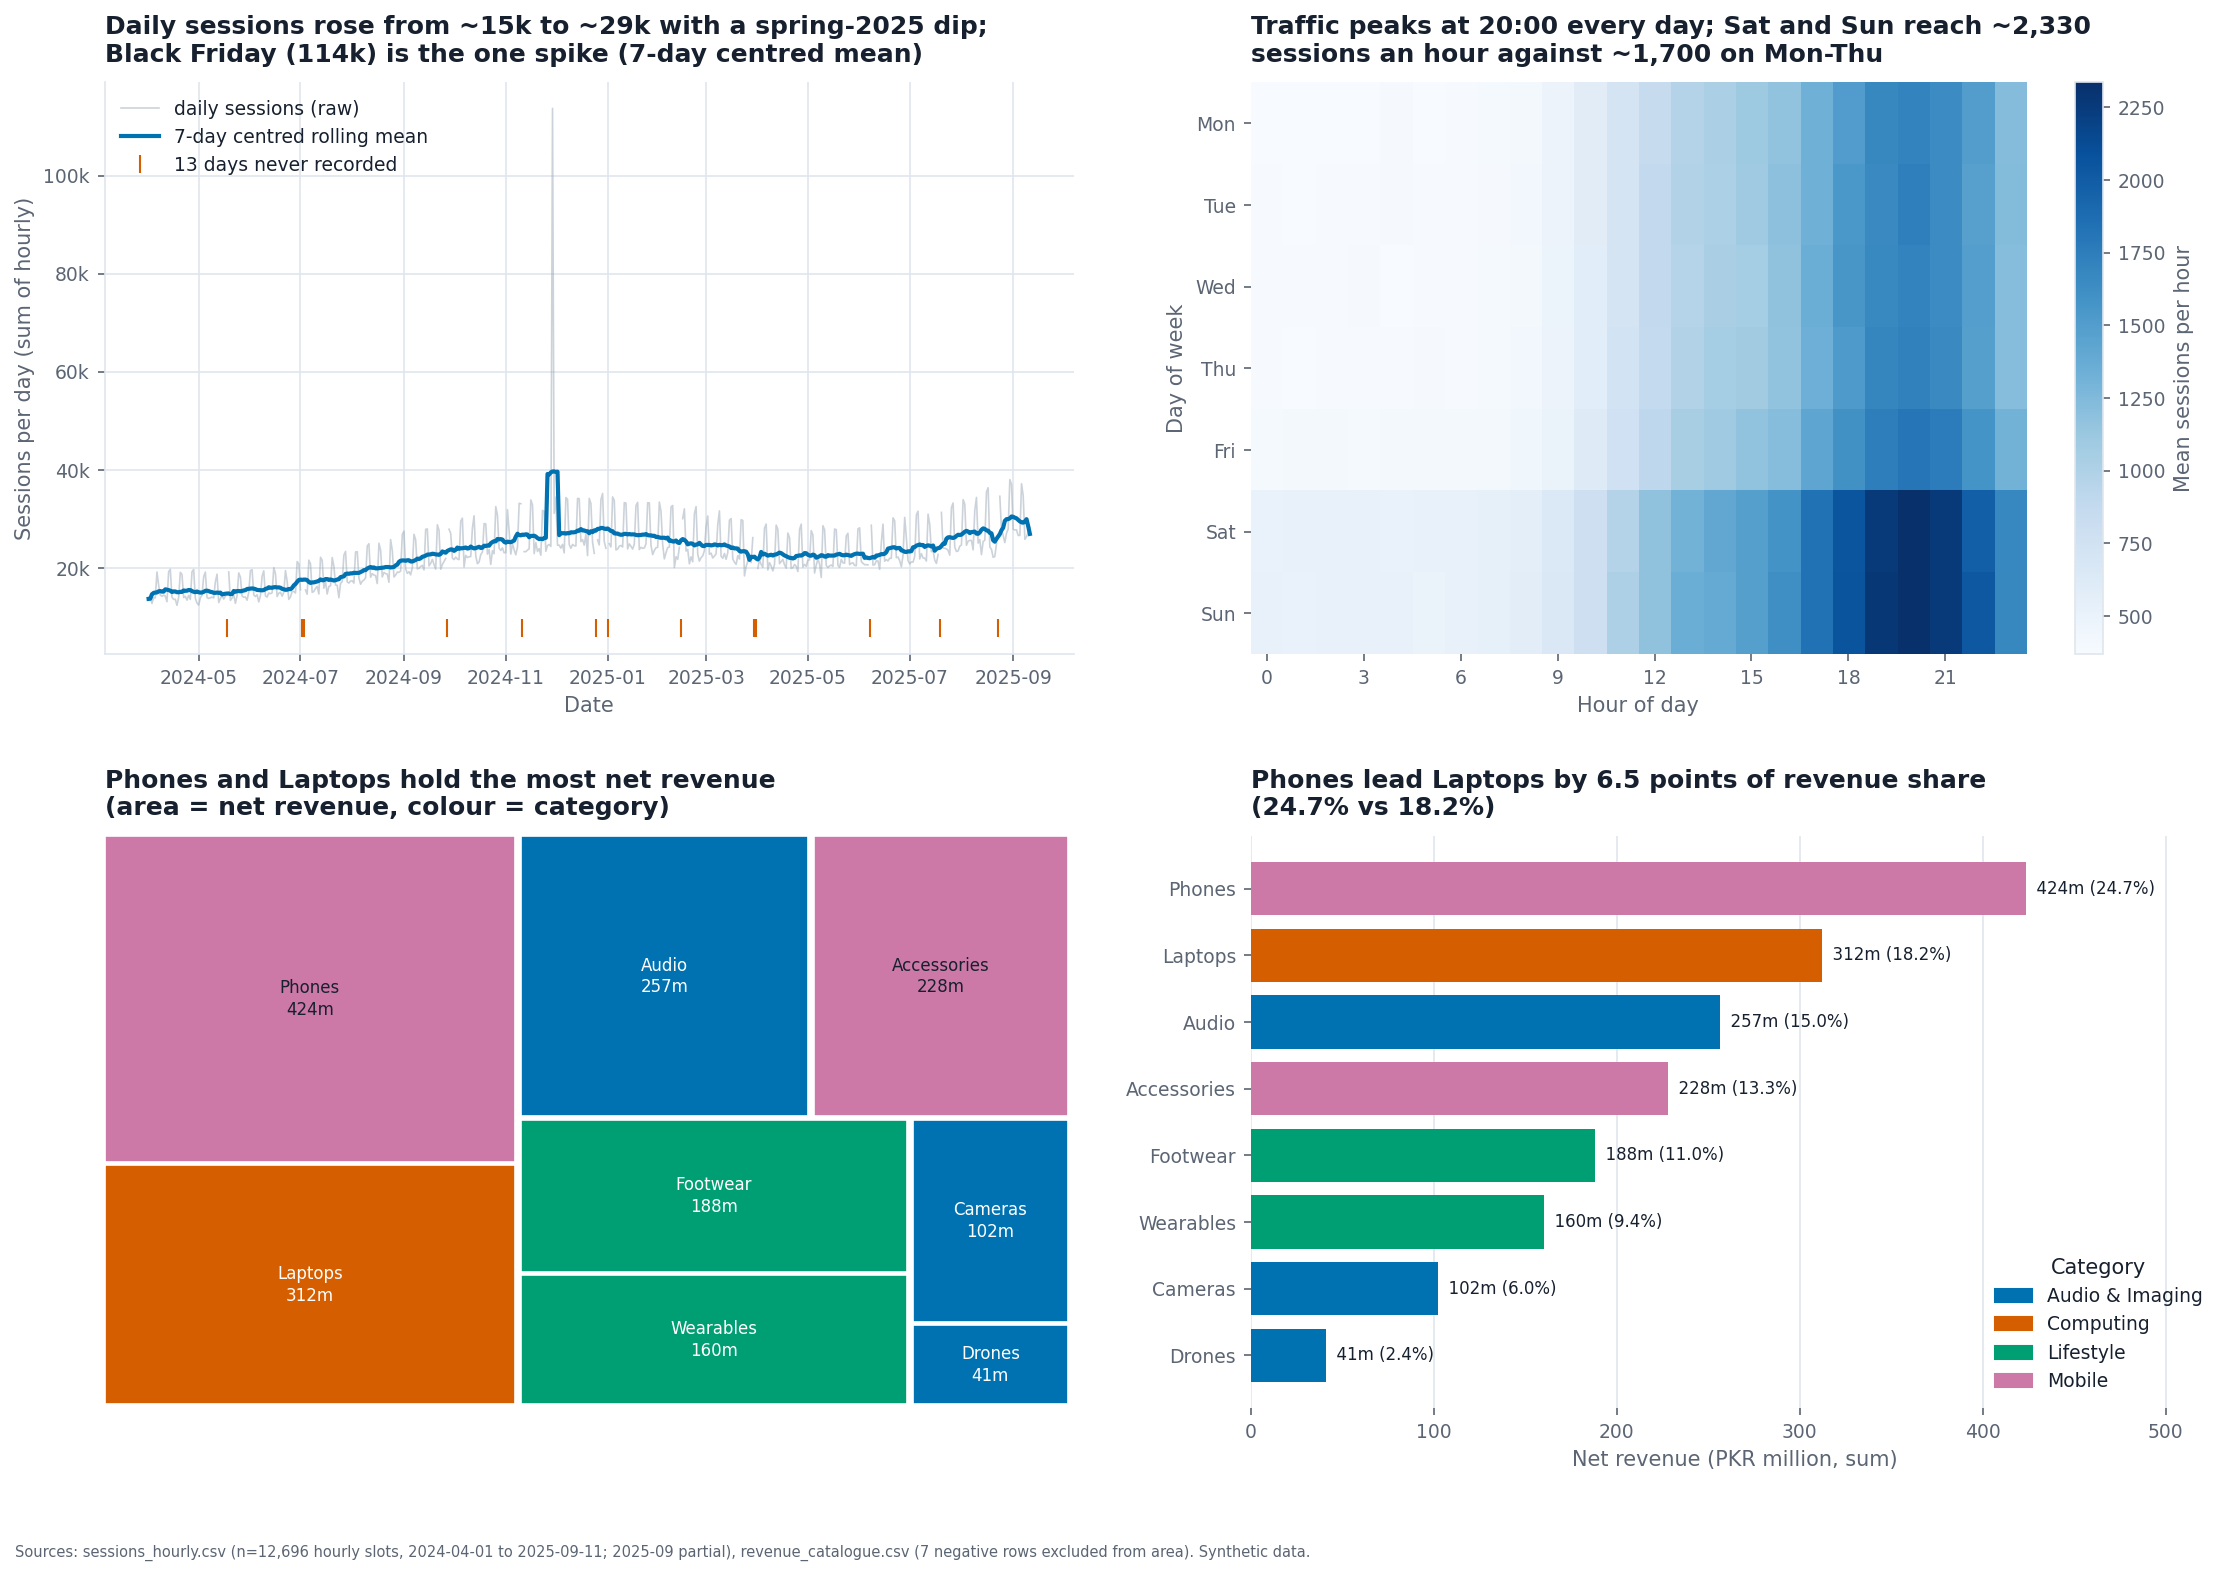

In [14]:
WINDOW = 7
DOW = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
smooth = daily.rolling(WINDOW, center=True, min_periods=WINDOW // 2 + 1).mean()
grey, blue = PALETTE["muted"], PALETTE["series"][0]

fig, ax = plt.subplots(2, 2, figsize=(15, 10))

a = ax[0, 0]                                    # panel 1: raw grey, named rolling mean
a.plot(daily.index, daily, color=grey, alpha=0.5, linewidth=0.8, label="daily sessions (raw)")
a.plot(smooth.index, smooth, color=blue, linewidth=2, label=f"{WINDOW}-day centred rolling mean")
gaps = daily[daily.isna()].index
a.plot(gaps, [daily.min() * 0.62] * len(gaps), "|", color=PALETTE["highlight"], markersize=9, label=f"{len(gaps)} days never recorded")
a.set_title(f"Daily sessions rose from ~15k to ~29k with a spring-2025 dip;\nBlack Friday (114k) is the one spike ({WINDOW}-day centred mean)")
a.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v/1000:.0f}k"))
a.set_xlabel("Date"); a.set_ylabel("Sessions per day (sum of hourly)"); a.legend(loc="upper left")

h = hourly.sessions.dropna().to_frame()         # panel 2: weekday x hour heatmap
grid = h.groupby([h.index.dayofweek, h.index.hour]).sessions.mean().unstack()
im = ax[0, 1].imshow(grid.values, aspect="auto", cmap="Blues")
ax[0, 1].set_yticks(range(7)); ax[0, 1].set_yticklabels(DOW); ax[0, 1].set_xticks(range(0, 24, 3))
ax[0, 1].set_title("Traffic peaks at 20:00 every day; Sat and Sun reach ~2,330\nsessions an hour against ~1,700 on Mon-Thu")
ax[0, 1].set_xlabel("Hour of day"); ax[0, 1].set_ylabel("Day of week"); ax[0, 1].grid(False)
fig.colorbar(im, ax=ax[0, 1], label="Mean sessions per hour")

cols = PALETTE["series"] + [PALETTE["series_4th"]]   # panel 3: treemap, one hue per parent
cmap = {p: cols[i] for i, p in enumerate(sorted(sub.category.unique()))}
tslib.treemap(ax[1, 0], sub.net_revenue_pkr_m.tolist(), labels=sub.subcategory.tolist(),
              values=sub.net_revenue_pkr_m.tolist(), colors=[cmap[p] for p in sub.category], value_fmt="{:,.0f}m")
ax[1, 0].set_title("Phones and Laptops hold the most net revenue\n(area = net revenue, colour = category)")
for t_ in ax[1, 0].texts:                       # white text fails on the pink 4th hue
    if t_.get_text().split("\n")[0] in set(sub[sub.category == "Mobile"].subcategory):
        t_.set_color(PALETTE["ink"])

s4 = sub.sort_values("net_revenue_pkr_m")       # panel 4: same eight as sorted bars, values printed
bars = ax[1, 1].barh(s4.subcategory, s4.net_revenue_pkr_m, color=[cmap[p] for p in s4.category])
for b, v, sh in zip(bars, s4.net_revenue_pkr_m, s4.share_pct):
    ax[1, 1].text(v, b.get_y() + b.get_height() / 2, f"  {v:,.0f}m ({sh:.1f}%)", va="center", fontsize=8)
ax[1, 1].set_xlim(0, s4.net_revenue_pkr_m.max() * 1.25)
ax[1, 1].set_title("Phones lead Laptops by 6.5 points of revenue share\n(24.7% vs 18.2%)")
from matplotlib.patches import Patch
ax[1, 1].legend(handles=[Patch(color=c_, label=p_) for p_, c_ in cmap.items()], title="Category", loc="lower right")
for sp_ in ("left", "bottom"): ax[1, 1].spines[sp_].set_visible(False)
for sp_ in ("left", "bottom", "top", "right"): ax[0, 1].spines[sp_].set_visible(False)
ax[1, 1].set_xlabel("Net revenue (PKR million, sum)"); ax[1, 1].grid(axis="y", visible=False)

fig.tight_layout(h_pad=2.5, w_pad=2.5)
note = (f"Sources: sessions_hourly.csv (n={len(hourly):,} hourly slots, {daily.index.min().date()} to {daily.index.max().date()}; "
        f"2025-09 partial), revenue_catalogue.csv ({len(neg)} negative rows excluded from area). Synthetic data.")
save(fig, "part_d_figure.png", note)      # savefig first
plt.show()

## 6. The cleaning log (feeds Part E)

In [15]:
pd.DataFrame(LOG)

,rule,rows,before,after
0,parse slash rows as dd/mm/yyyy,3651,NaT with default parse: 3651,NaT: 0
1,device spelling normalised (strip + title case),1447,6 labels,3 labels
2,exact duplicate rows dropped,286,12670 rows,12384 rows
3,sessions == -1 sentinel -> NaN,287,min sessions -1,min 179
4,"hours never recorded: reindexed, left NaN",312,12384 rows,12696 on full calendar
5,daily = sum(min_count=1); gap days stay NaN,13,0 NaN days if plain sum(),13 NaN days
6,partial final month: data ends 2025-09-11,11,Sep 2025 has 30 days,11 recorded
7,"catalogue: duplicate SKU, keep first",1,345 rows,344 rows
8,catalogue: negative net revenue split out (no ...,7,net 1711.38m,1712.45m positive; -1.069m shown separately


## 7. What each panel answers (one sentence each, my words)
1. **Is traffic growing, and is anything unusual?** Weekly rhythm removed by a 7-day mean, the line roughly doubles from ~15k to ~29k sessions a day (with a winter peak and a spring-2025 dip) and the only event outside the pattern is Black Friday, 113,710 against a normal ~25k.
2. **When in the week and day do people visit?** At 20:00 every day, and Saturday and Sunday run about a third higher than Monday to Thursday (~2,330 vs ~1,700 sessions an hour at the peak).
3. **Where is the revenue mass?** (the treemap) Phones is the largest single block, Mobile (Phones plus Accessories, 652m, 38% of positive net revenue) is the largest category, and the small blocks are Cameras and Drones.
4. **By how much does each sub-category differ?** (the bars) Phones lead Laptops by 6.5 points (24.7% vs 18.2%), Audio sits at 15.0%, and Drones are only 2.4%, which the treemap shows as small but cannot put a number on.